## Top Genes Predicted to be admixed for each cell type and overlap analysis

In [44]:
import anndata as ad
import re
import numpy as np
import pandas as pd
import scanpy as sc
import scib_metrics
from scipy import sparse

train_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_100th_train_med_with_admix_probs.h5ad')
val_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_100th_val_med_with_admix_probs.h5ad')
train_data.uns['neighbor_celltype_dict'].update(val_data.uns['neighbor_celltype_dict'])
train_data.uns['neighbor_dict'].update(val_data.uns['neighbor_dict'])
sc_data = ad.concat([train_data,val_data],uns_merge="first",join='outer')
[c for c in list(sc_data.uns['neighbor_celltype_dict'].keys()) if c.startswith('p5t1-bcAAEL-8')]

['p5t1-bcAAEL-8']

In [46]:
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSE127465_tumor_integrated_hardcap_100th_train_med_with_admix_probs.h5ad')

In [47]:
import pandas as pd
import numpy as np

# Assumes:
# - adata.obs["cell_type"] has cell type labels
# - adata.obsm["admix_probs"] is cells x genes/topics/features
# - columns correspond to adata.var_names

admix = pd.DataFrame(
    sc_data.layers["admix_probs"].toarray(),
    index=sc_data.obs_names,
    columns=sc_data.var_names,
)

admix["cell_type"] = sc_data.obs["cell_type"].values

# Mean admix_probs per gene within each cell type
mean_admix_by_cell_type = admix.groupby("cell_type").mean()

# Long ranked table: one row per cell_type/gene
gene_symbols = sc_data.var["gene_symbol"].reindex(sc_data.var_names)

ranked_genes = (
    mean_admix_by_cell_type
    .stack()
    .reset_index()
    .rename(columns={
        "level_0": "cell_type",
        "level_1": "gene",
        0: "mean_admix_prob",
    })
    .sort_values(["cell_type", "mean_admix_prob"], ascending=[True, False])
)

ranked_genes["gene_symbol"] = ranked_genes['index'].map(gene_symbols)

ranked_genes["rank"] = (
    ranked_genes
    .groupby("cell_type")["mean_admix_prob"]
    .rank(method="first", ascending=False)
    .astype(int)
)

ranked_genes

/tmp/ipykernel_1001669/3610833603.py:18: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  mean_admix_by_cell_type = admix.groupby("cell_type").mean()
/tmp/ipykernel_1001669/3610833603.py:39: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("cell_type")["mean_admix_prob"]


,cell_type,index,mean_admix_prob,gene_symbol,rank
849,B-cell,ENSG00000196352,0.121932,CD55,1
144,B-cell,ENSG00000100644,0.088155,HIF1A,2
122,B-cell,ENSG00000092820,0.084256,EZR,3
495,B-cell,ENSG00000143761,0.074900,ARF1,4
164,B-cell,ENSG00000102760,0.073735,RGCC,5
...,...,...,...,...,...
14322,tumor,ENSG00000240505,0.000000,TNFRSF13B,953
14333,tumor,ENSG00000254647,0.000000,INS,954
14335,tumor,ENSG00000256039,0.000000,LINC02446,955
14341,tumor,ENSG00000266524,0.000000,GDF10,956


/tmp/ipykernel_1001669/389335426.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("cell_type")
/tmp/ipykernel_1001669/389335426.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("cell_type")
/home/jwinchel/miniconda3/envs/heimdall/lib/python3.10/site-packages/upsetplot/data.py:385: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/home/jwinc

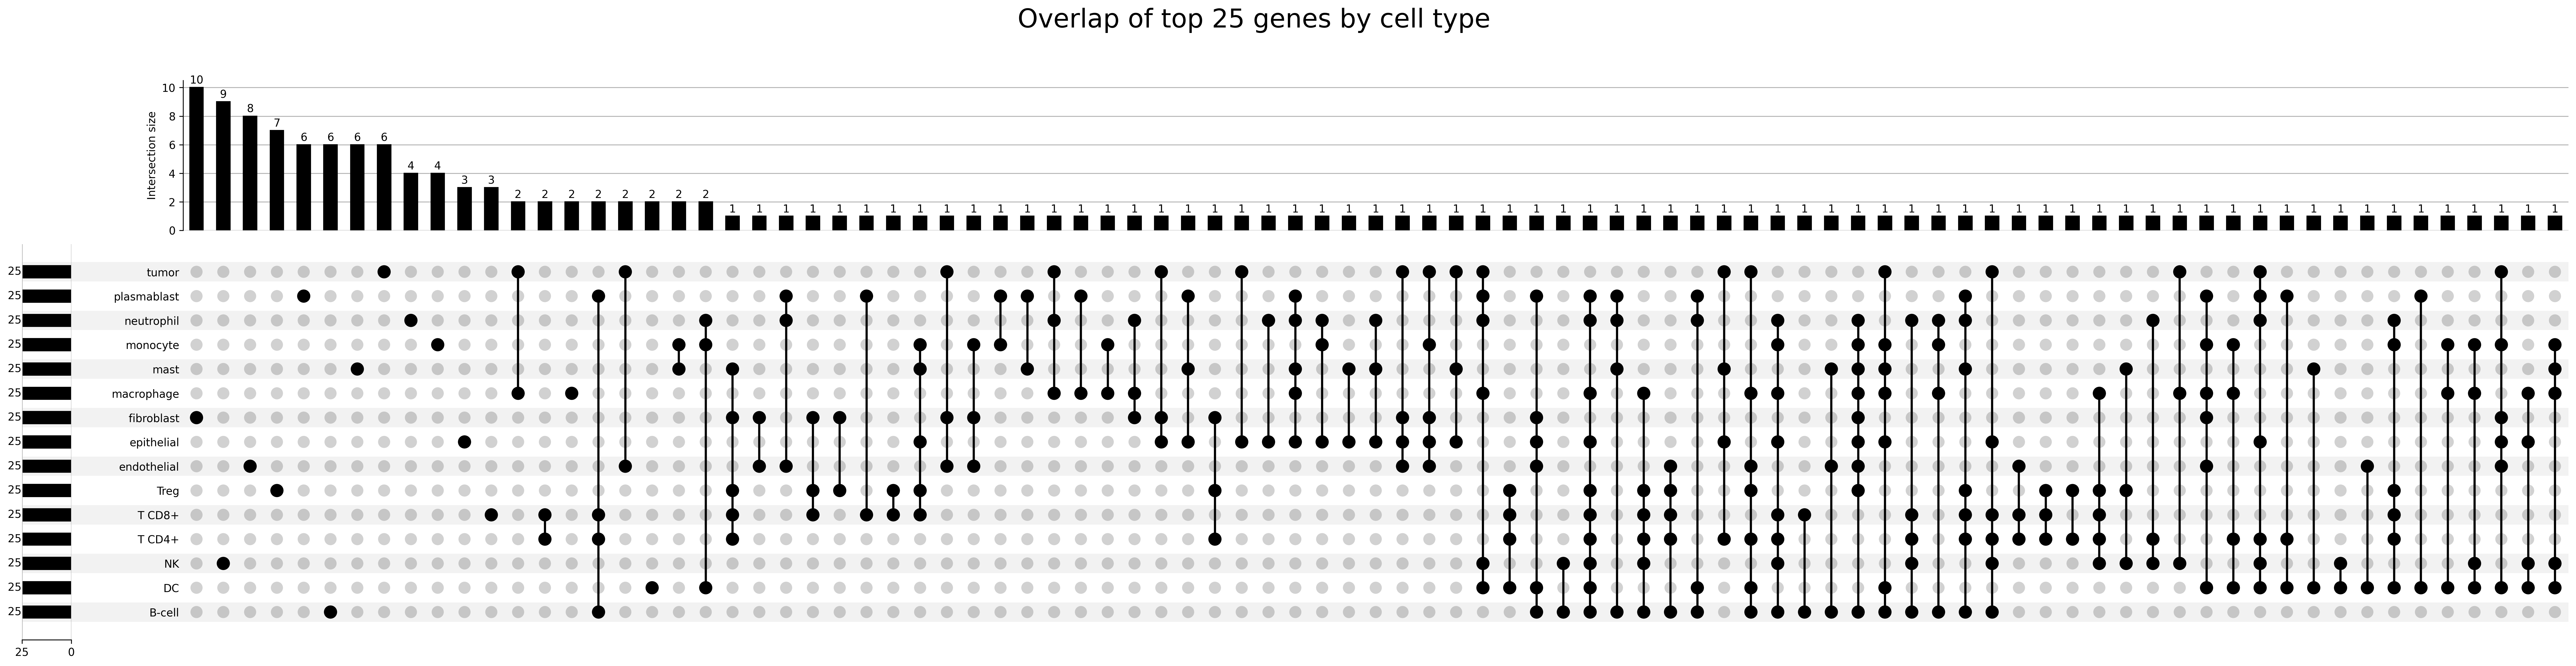

In [51]:
# pip install upsetplot
from upsetplot import from_contents, UpSet
import matplotlib.pyplot as plt

top_n = 25

gene_sets = {
    cell_type: set(df["index"])
    for cell_type, df in (
        ranked_genes
        .sort_values(["cell_type", "rank"])
        .groupby("cell_type")
        .head(top_n)
        .groupby("cell_type")
    )
}

upset_data = from_contents(gene_sets)

fig = plt.figure(figsize=(12, 7), dpi=300)
UpSet(
    upset_data,
    show_counts=True,
    sort_by="cardinality",
).plot(fig=fig)

plt.suptitle(f"Overlap of top {top_n} genes by cell type",fontsize=24)
plt.show()

In [32]:
import pandas as pd
import numpy as np

# cells x genes predictions
X = sc_data.layers["admix_probs"]
if hasattr(X, "toarray"):
    X = X.toarray()

pred = pd.DataFrame(
    X,
    index=sc_data.obs_names,
    columns=sc_data.var_names,
)

# Add focal cell type for each cell
pred["cell_type"] = sc_data.obs["cell_type"].values

# Convert neighbor dict into long table:
# one row per cell / neighbor_cell_type occurrence
neighbor_long = (
    pd.Series(sc_data.uns['neighbor_celltype_dict'], name="neighbor_cell_type")
    .explode()
    .reset_index()
    .rename(columns={"index": "cell"})
)

# Optional: keep duplicate neighbor labels as weights.
# Example: macrophage appearing 2 of 3 times counts more.
neighbor_long["neighbor_count"] = 1

neighbor_counts = (
    neighbor_long
    .groupby(["cell", "neighbor_cell_type"], as_index=False)
    .agg(neighbor_count=("neighbor_count", "sum"))
)
neighbor_counts.index = neighbor_counts['cell']

# Join focal cell type

neighbor_counts["cell_type"] = sc_data.obs.loc[
    neighbor_counts["cell"], "cell_type"
].values

In [42]:
# Long predictions: one row per cell / gene
pred_long = (
    pred
    .drop(columns="cell_type")
    .stack()
    .reset_index()
    .rename(columns={
        "level_0": "cell",
        "level_1": "gene",
        0: "prediction",
    })
)

# Attach neighbor contexts
neighbor_gene_predictions = pred_long.merge(
    neighbor_counts,
    left_on='cell_ID_long',
    right_index=True,
    how="inner",
)


neighbor_gene_predictions = neighbor_gene_predictions.rename(columns={'index':'gene'})
# Weighted mean prediction per focal cell type, neighbor cell type, gene
ranked_neighbor_genes = (
    neighbor_gene_predictions
    .assign(weighted_prediction=lambda x: x["prediction"] * x["neighbor_count"])
    .groupby(["cell_type", "neighbor_cell_type", "gene"], as_index=False)
    .agg(
        mean_prediction=("prediction", "mean"),
        weighted_mean_prediction=("weighted_prediction", "sum"),
        total_neighbor_count=("neighbor_count", "sum"),
        n_cells=("cell", "nunique"),
    )
)

ranked_neighbor_genes["weighted_mean_prediction"] = (
    ranked_neighbor_genes["weighted_mean_prediction"]
    / ranked_neighbor_genes["total_neighbor_count"]
)

/tmp/ipykernel_1001669/1995562933.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  neighbor_gene_predictions


ValueError: Length of values (176088) does not match length of index (200970)